# Reducción de dimensionalidad con PCA y t-SNE, y modelado de temas con LDA

## Objetivo

Reducir a dos dimensiones un conjunto de datos de comentarios etiquetados (odio / no odio), representar los resultados y seleccionar la técnica más adecuada para estos datos. Como complemento, se extraen temas latentes del texto con LDA.

### Objetivos específicos
* Aplicar **PCA** (lineal) y **t-SNE** (no lineal) sobre las variables numéricas estandarizadas.
* Comparar las proyecciones obtenidas y evaluar si separan las etiquetas.
* Aplicar **LDA** (*Latent Dirichlet Allocation*) para obtener una bolsa de palabras por tema y por etiqueta.

#### Preparación del entorno

Se importan las librerías necesarias y se fija una configuración reproducible para el análisis. Esta preparación permite trabajar de forma ordenada con los datos, generar las representaciones gráficas y aplicar los modelos de reducción de dimensionalidad sin repetir código en cada apartado.

In [1]:

# Librerías principales
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
import re
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, LatentDirichletAllocation
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


### Dataset

#### Descripción inicial del conjunto de datos

Antes de aplicar PCA, t-SNE o LDA se identifica la estructura del dataset: número de registros, variables disponibles, presencia de texto y existencia de una etiqueta. Esta revisión inicial permite separar correctamente las variables numéricas, que se usarán en la reducción de dimensionalidad, de la columna textual, que se utilizará posteriormente en el análisis de temas.

#### Dataset

El conjunto de datos utilizado contiene 10.000 registros y 22 columnas. Cada registro corresponde a un comentario previamente tratado y a un conjunto de variables numéricas extraídas a partir de dicho texto. La variable `label` contiene dos categorías, con una distribución equilibrada: 5.000 observaciones pertenecen a la clase 0 y 5.000 a la clase 1. Este equilibrio es importante, porque evita que las visualizaciones y las evaluaciones posteriores estén dominadas por una clase mayoritaria.

El dataset original ha sido adaptado previamente. La adaptación incluye eliminación de valores nulos y duplicados, limpieza de URLs, emojis y menciones, eliminación de filas vacías, homogeneización del texto, conversión a minúsculas, eliminación de signos de puntuación, eliminación de números, reducción de espacios en blanco, eliminación de palabras muy cortas, retirada de stopwords, tokenización y lematización. Por tanto, la columna `comentario` no contiene texto bruto, sino una versión ya procesada y más adecuada para el análisis de lenguaje natural.

Además del texto, el dataset incorpora variables numéricas construidas a partir de características del comentario. Las variables `A`, `B`, `C`, `D` y `E` recogen información cuantitativa como conteo de palabras positivas, conteo de palabras negativas, número de bigramas frecuentes, menciones a otros usuarios y categoría de sentimiento obtenida mediante una herramienta de análisis de sentimiento en español. También aparecen las variables transformadas `A_t`, `B_t`, `C_t`, `D_t` y `E_t`, que representan versiones estandarizadas o transformadas de esas características. Finalmente, las columnas `Valor_1` a `Valor_10` corresponden a combinaciones derivadas de las variables anteriores.

Para PCA y t-SNE se trabaja únicamente con variables numéricas, ya que ambos métodos requieren una representación vectorial de los datos. La columna `comentario` se reserva para el apartado de LDA, donde el objetivo es extraer temas y bolsas de palabras. La columna `label` no se utiliza como variable de entrada para calcular PCA ni t-SNE, sino como referencia para colorear las representaciones y analizar si la estructura reducida separa correctamente las dos clases.

### Lectura de datos

#### Lectura del dataset

Se carga el archivo `out.csv` y se muestra una primera vista del contenido. Este paso permite comprobar que el fichero se ha leído correctamente y que las columnas esperadas están disponibles antes de iniciar el análisis exploratorio.

In [2]:

# Leer el archivo CSV
candidate_paths = [
    'data/out.csv',
    'out.csv',
]

file_path = None
for path in candidate_paths:
    if os.path.exists(path):
        file_path = path
        break

if file_path is None:
    raise FileNotFoundError(
        "No se ha encontrado out.csv. Coloca el archivo en la misma carpeta del notebook "
        "o modifica candidate_paths con la ruta correcta."
    )

print('Archivo utilizado:', file_path)
data = pd.read_csv(file_path)

# Obtener el número de filas y columnas
num_filas, num_columnas = data.shape
print(f"El dataset tiene {num_filas} filas y {num_columnas} columnas.")

print(data.head().to_string())


Archivo utilizado: out.csv


El dataset tiene 10000 filas y 22 columnas.
   A   B   C  D  E                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

#### Revisión de la etiqueta

La variable `label` se utiliza como referencia para colorear las representaciones bidimensionales y comparar si la estructura encontrada por PCA y t-SNE coincide con las clases existentes. No se emplea como variable de entrada en la reducción de dimensionalidad, sino como apoyo para interpretar los resultados.

Número de categorías diferentes en label: 2
       frecuencia
label            
0.0          5000
1.0          5000


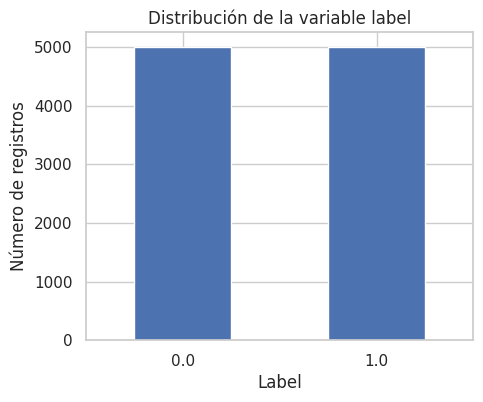

In [3]:

# Cuántas categorías hay en la columna label
label_counts = data['label'].value_counts().sort_index()
num_labels = data['label'].nunique()

print(f"Número de categorías diferentes en label: {num_labels}")
print(label_counts.to_frame(name='frecuencia').to_string())

plt.figure(figsize=(5, 4))
label_counts.plot(kind='bar')
plt.title('Distribución de la variable label')
plt.xlabel('Label')
plt.ylabel('Número de registros')
plt.xticks(rotation=0)
plt.show()


#### Análisis exploratorio básico

Se calculan estadísticas descriptivas y valores nulos para evaluar la calidad de los datos. En este caso, el dataset no presenta valores perdidos, por lo que no es necesario aplicar imputación ni eliminar registros antes de construir las representaciones.

In [4]:
# Análisis descriptivo de las variables
numeric_cols = data.select_dtypes(include=['number']).columns.tolist()
print(f'Se han detectado {len(numeric_cols)} variables numéricas: {numeric_cols}')

if len(numeric_cols) > 0:
    stats_numeric = data[numeric_cols].describe().T.round(3)
    print('\nEstadísticas descriptivas de las variables numéricas:')
    print(stats_numeric.to_string())
else:
    stats_numeric = pd.DataFrame()
    print('\nNo se han detectado variables numéricas en el dataset.')

if 'label' in data.columns:
    frecuencia_label = data['label'].value_counts(normalize=False).sort_index()
    porcentaje_label = (data['label'].value_counts(normalize=True).sort_index() * 100).round(2)

    label_table = pd.DataFrame({
        'frecuencia': frecuencia_label,
        'porcentaje': porcentaje_label
    })

    print('\nFrecuencia y porcentaje de label:')
    print(label_table.to_string())
else:
    label_table = pd.DataFrame()
    print('\nNo se encuentra la columna label.')

print('\nValores nulos por columna:')
nulos_table = data.isna().sum().to_frame(name='nulos')
print(nulos_table.to_string())

Se han detectado 21 variables numéricas: ['A', 'B', 'C', 'D', 'E', 'label', 'A_t', 'B_t', 'C_t', 'D_t', 'E_t', 'Valor_1', 'Valor_2', 'Valor_3', 'Valor_4', 'Valor_5', 'Valor_6', 'Valor_7', 'Valor_8', 'Valor_9', 'Valor_10']

Estadísticas descriptivas de las variables numéricas:
            count    mean     std     min    25%    50%     75%      max
A         10000.0   0.957   1.742   0.000  0.000  0.000   1.000   24.000
B         10000.0  26.098  34.012   0.000  1.000  5.000  46.000  328.000
C         10000.0   5.675   7.317   0.000  1.000  3.000   7.000   88.000
D         10000.0   0.091   0.353   0.000  0.000  0.000   0.000    6.000
E         10000.0   2.201   2.729   0.000  0.000  0.000   6.000    6.000
label     10000.0   0.500   0.500   0.000  0.000  0.500   1.000    1.000
A_t       10000.0   0.736   1.863  -0.288 -0.288 -0.288   0.782   25.381
B_t       10000.0   0.895   1.673  -0.388 -0.339 -0.142   1.874   15.745
C_t       10000.0   1.014   1.844  -0.416 -0.164  0.340   1.348   

#### Visualización exploratoria

Las distribuciones y la matriz de correlación permiten observar la escala, dispersión y relación entre las variables numéricas. Esta información es relevante porque PCA trabaja con varianza y correlaciones, mientras que t-SNE depende de relaciones de proximidad entre observaciones.

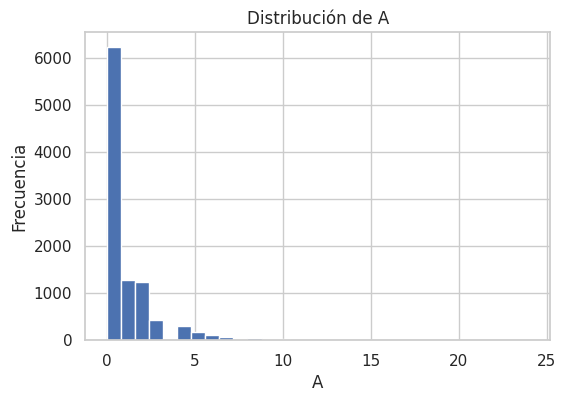

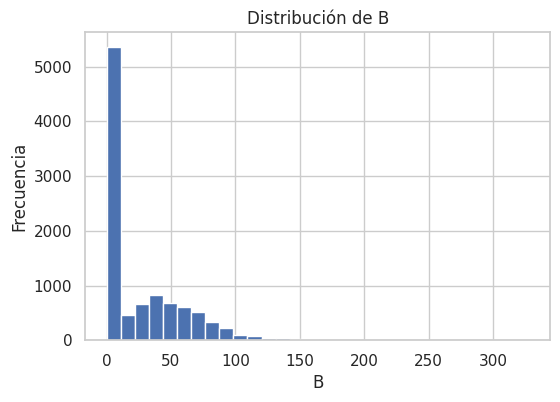

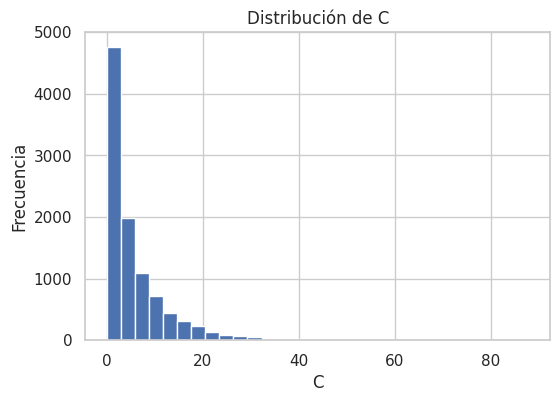

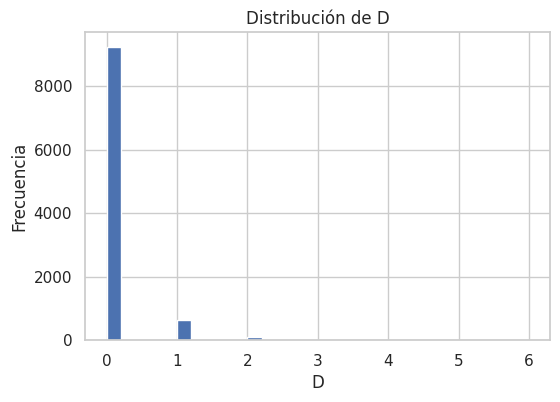

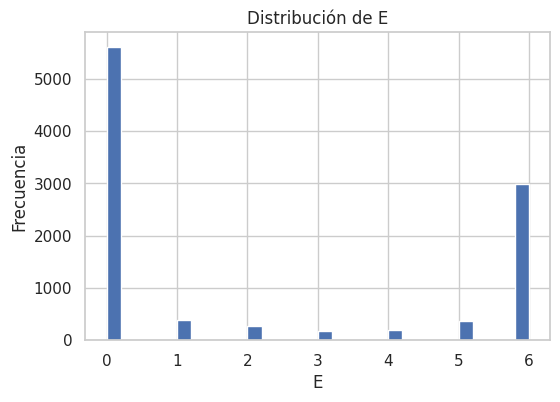

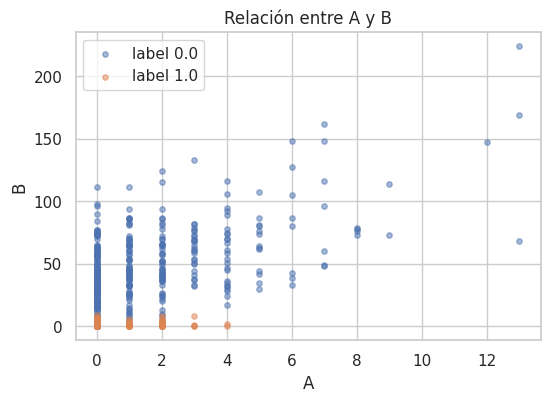

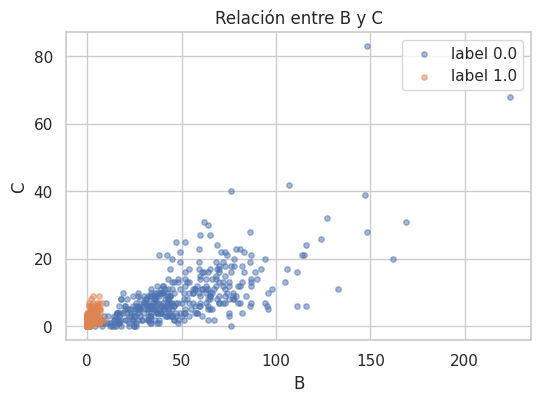

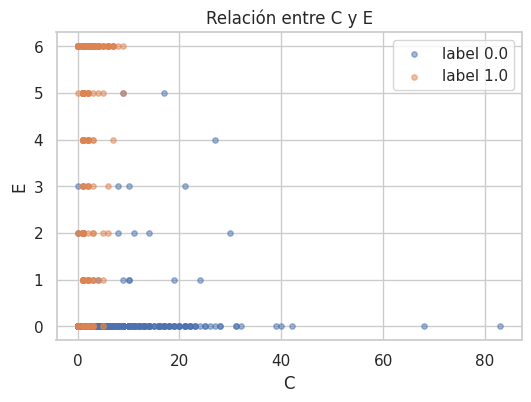

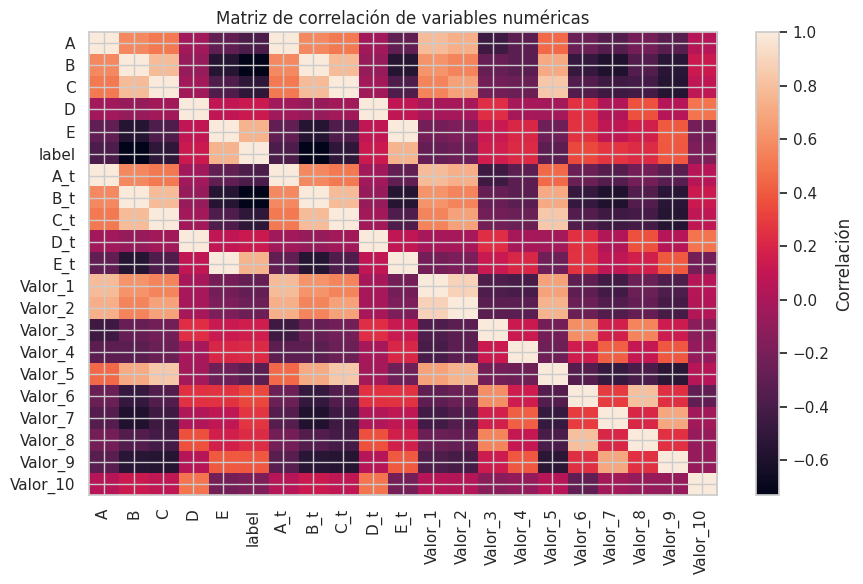

In [5]:

# Visualización exploratoria básica
# Se utiliza una muestra para que los gráficos sean claros y rápidos de generar.

eda_cols = ['A', 'B', 'C', 'D', 'E']
eda_cols = [c for c in eda_cols if c in data.columns]
sample_eda = data[eda_cols + ['label']].sample(min(800, len(data)), random_state=RANDOM_STATE)

# Histogramas de las variables principales
for col in eda_cols:
    plt.figure(figsize=(6, 4))
    plt.hist(data[col], bins=30)
    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.show()

# Gráficos de dispersión sencillos por pares de variables
pairs = [('A', 'B'), ('B', 'C'), ('C', 'E')]
for x_col, y_col in pairs:
    if x_col in sample_eda.columns and y_col in sample_eda.columns:
        plt.figure(figsize=(6, 4))
        for label_value in sorted(sample_eda['label'].unique()):
            subset = sample_eda[sample_eda['label'] == label_value]
            plt.scatter(subset[x_col], subset[y_col], s=15, alpha=0.5, label=f'label {label_value}')
        plt.title(f'Relación entre {x_col} y {y_col}')
        plt.xlabel(x_col)
        plt.ylabel(y_col)
        plt.legend()
        plt.show()

# Matriz de correlación
corr = data[numeric_cols].corr()
plt.figure(figsize=(9, 6))
plt.imshow(corr, aspect='auto')
plt.colorbar(label='Correlación')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title('Matriz de correlación de variables numéricas')
plt.tight_layout()
plt.show()


#### Análisis exploratorio de datos

El conjunto de datos contiene 10.000 registros y 22 columnas. La variable `label` presenta dos categorías con 5.000 observaciones en cada una, por lo que el dataset está equilibrado respecto a la etiqueta. Esta distribución facilita la interpretación posterior de las gráficas, ya que una clase no domina numéricamente a la otra.

No se observan valores nulos en ninguna columna. Por tanto, el análisis puede continuar sin imputación ni eliminación de filas. Las variables numéricas muestran escalas diferentes y algunas distribuciones con dispersión elevada, por lo que el escalado previo resulta necesario antes de aplicar PCA y t-SNE.

#### Selección de variables numéricas

Se conservan las variables numéricas relacionadas con el análisis principal y se separa la columna de texto. PCA y t-SNE requieren una matriz numérica, mientras que el texto se analiza después mediante LDA.

In [6]:

# Eliminar columnas que empiecen por 'Valor_' y la columna 'comentario'
# Se conserva label porque es la variable usada para colorear y evaluar las representaciones.

valor_cols = [col for col in data.columns if col.startswith('Valor_')]
cols_to_drop = valor_cols + ['comentario']

model_data = data.drop(columns=cols_to_drop, errors='ignore').copy()

# La etiqueta se trata como variable categórica para el análisis posterior.
model_data['label'] = model_data['label'].astype(int)

print('Columnas eliminadas:', cols_to_drop)
print('Columnas conservadas para el análisis numérico:')
print(model_data.columns.tolist())

print(model_data.head().to_string())


Columnas eliminadas: ['Valor_1', 'Valor_2', 'Valor_3', 'Valor_4', 'Valor_5', 'Valor_6', 'Valor_7', 'Valor_8', 'Valor_9', 'Valor_10', 'comentario']
Columnas conservadas para el análisis numérico:
['A', 'B', 'C', 'D', 'E', 'label', 'A_t', 'B_t', 'C_t', 'D_t', 'E_t']
   A   B   C  D  E  label       A_t       B_t        C_t       D_t       E_t
0  2  64  30  0  2      0  1.851102  2.759647   7.145831 -0.416577  0.440638
1  4  70  21  0  0      0  3.990202  3.054765   4.877255 -0.416577 -0.531099
2  4  88  50  0  0      0  3.990202  3.940120  12.187108 -0.416577 -0.531099
3  3  38  21  0  0      0  2.920652  1.480801   4.877255 -0.416577 -0.531099
4  0  59  17  0  0      0 -0.287998  2.513715   3.869000 -0.416577 -0.531099


#### Estandarización de variables

Las variables se escalan para que tengan media cercana a cero y desviación típica cercana a uno. Esta transformación evita que las variables con mayor escala dominen artificialmente la reducción de dimensionalidad.

In [7]:
# Estandarización de variables
feature_cols = [col for col in model_data.columns if col != 'label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(model_data[feature_cols])

scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)
scaled_df['label'] = model_data['label'].values

media_scaled = scaled_df[feature_cols].mean().round(4).to_frame('media')
desviacion_scaled = scaled_df[feature_cols].std().round(4).to_frame('desviacion_tipica')

print('Media aproximada tras estandarizar:')
print(media_scaled.to_string())

print('\nDesviación típica aproximada tras estandarizar:')
print(desviacion_scaled.to_string())

Media aproximada tras estandarizar:
     media
A      0.0
B      0.0
C      0.0
D     -0.0
E     -0.0
A_t   -0.0
B_t    0.0
C_t    0.0
D_t   -0.0
E_t   -0.0

Desviación típica aproximada tras estandarizar:
     desviacion_tipica
A               1.0001
B               1.0001
C               1.0001
D               1.0001
E               1.0001
A_t             1.0001
B_t             1.0001
C_t             1.0001
D_t             1.0001
E_t             1.0001


#### Separación entre características y etiqueta

La matriz `X` contiene las variables numéricas que se proyectan a dos dimensiones. La variable `y`, correspondiente a `label`, se reserva para colorear gráficos y evaluar de forma exploratoria si las representaciones separan adecuadamente las dos clases.

In [8]:

# Separar las características y las etiquetas
X = scaled_df[feature_cols].values
y = scaled_df['label'].values

print('Dimensión de X:', X.shape)
print('Dimensión de y:', y.shape)
print('Variables utilizadas:', feature_cols)


Dimensión de X: (10000, 10)
Dimensión de y: (10000,)
Variables utilizadas: ['A', 'B', 'C', 'D', 'E', 'A_t', 'B_t', 'C_t', 'D_t', 'E_t']


#### Tratamiento de variables

Para la reducción de dimensionalidad se utilizan las variables `A`, `B`, `C`, `D`, `E` y sus transformaciones `A_t`, `B_t`, `C_t`, `D_t`, `E_t`. La columna `comentario` se excluye de PCA y t-SNE porque estos métodos requieren variables numéricas. La columna `label` se separa de la matriz de entrada y se conserva únicamente como referencia para interpretar las representaciones.

Después del escalado, las variables presentan media aproximada igual a 0 y desviación típica próxima a 1. Esto confirma que todas las características entran en el análisis en una escala comparable, evitando que variables como `B` o `C`, con rangos más amplios, tengan más peso solo por su magnitud original.

### PCA

#### Aplicación de PCA

PCA se aplica sobre las variables estandarizadas para obtener dos componentes principales. El objetivo es resumir la mayor cantidad posible de variabilidad del dataset en un plano bidimensional interpretable.

In [9]:

# Aplicar PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)

# Crear un DataFrame con los resultados de PCA
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['label'] = y

explained_var = pca.explained_variance_ratio_
explained_total = explained_var.sum()

print('Varianza explicada por PC1:', round(explained_var[0], 4))
print('Varianza explicada por PC2:', round(explained_var[1], 4))
print('Varianza explicada acumulada:', round(explained_total, 4))

print(pca_df.head().to_string())

loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=['PC1', 'PC2']
)
print('Contribución de las variables a cada componente:')
print(loadings.round(3).to_string())


Varianza explicada por PC1: 0.5184
Varianza explicada por PC2: 0.2003
Varianza explicada acumulada: 0.7186
        PC1       PC2  label
0  3.863271  0.257069      0
1  4.253772  0.127813      0
2  7.663432  0.736383      0
3  3.115034  0.001730      0
4  2.094273 -0.313390      0
Contribución de las variables a cada componente:
       PC1    PC2
A    0.323  0.076
B    0.408  0.021
C    0.376  0.074
D   -0.051  0.693
E   -0.292  0.087
A_t  0.323  0.076
B_t  0.408  0.021
C_t  0.376  0.074
D_t -0.051  0.693
E_t -0.292  0.087


#### Representación bidimensional de PCA

La gráfica de `PC1` y `PC2` permite valorar visualmente si las dos componentes principales generan una separación clara entre las etiquetas. Esta interpretación se complementa con la varianza explicada y con una prueba de clasificación exploratoria.

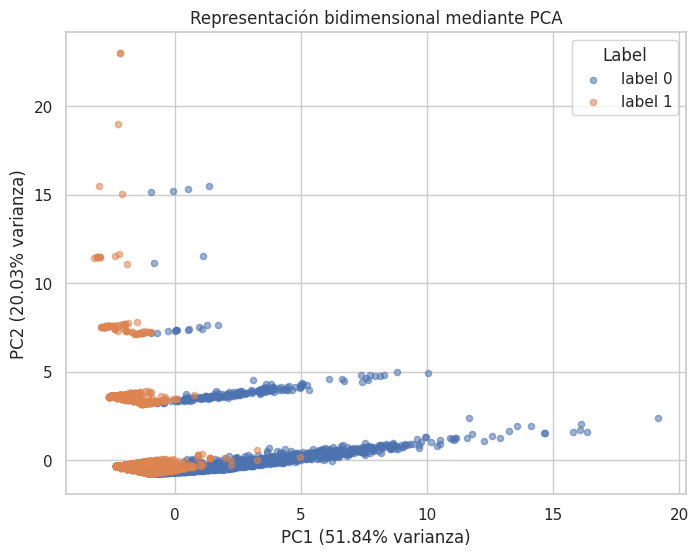

In [10]:

# Visualizar los resultados de PCA
plt.figure(figsize=(8, 6))
for label_value in sorted(pca_df['label'].unique()):
    subset = pca_df[pca_df['label'] == label_value]
    plt.scatter(subset['PC1'], subset['PC2'], s=20, alpha=0.55, label=f'label {label_value}')
plt.title('Representación bidimensional mediante PCA')
plt.xlabel(f"PC1 ({explained_var[0]*100:.2f}% varianza)")
plt.ylabel(f"PC2 ({explained_var[1]*100:.2f}% varianza)")
plt.legend(title='Label')
plt.show()


#### Evaluación exploratoria sobre PCA

Se entrena un clasificador sencillo utilizando únicamente las dos componentes de PCA. Esta prueba no sustituye a un estudio supervisado completo, pero ayuda a comprobar si la información conservada en dos dimensiones sigue siendo útil para distinguir las etiquetas.

Accuracy usando solo las dos componentes de PCA: 0.9728

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1250
           1       0.97      0.98      0.97      1250

    accuracy                           0.97      2500
   macro avg       0.97      0.97      0.97      2500
weighted avg       0.97      0.97      0.97      2500



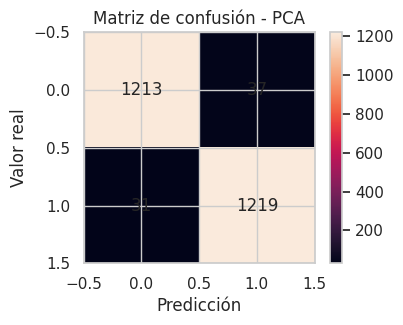

In [11]:

# Dividir los datos en conjunto de entrenamiento y prueba
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    pca_df[['PC1', 'PC2']],
    pca_df['label'],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=pca_df['label']
)

# Entrenar un modelo de clasificación sencillo sobre las dos componentes de PCA
rf_pca = RandomForestClassifier(n_estimators=80, random_state=RANDOM_STATE, n_jobs=-1)
rf_pca.fit(X_train_pca, y_train_pca)

# Predecir y evaluar el modelo
y_pred_pca = rf_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test_pca, y_pred_pca)

print('Accuracy usando solo las dos componentes de PCA:', round(acc_pca, 4))
print('\nInforme de clasificación:')
print(classification_report(y_test_pca, y_pred_pca))

cm_pca = confusion_matrix(y_test_pca, y_pred_pca)
plt.figure(figsize=(4, 3))
plt.imshow(cm_pca)
plt.title('Matriz de confusión - PCA')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.colorbar()
for i in range(cm_pca.shape[0]):
    for j in range(cm_pca.shape[1]):
        plt.text(j, i, cm_pca[i, j], ha='center', va='center')
plt.show()


#### Análisis de los resultados obtenidos por PCA

PCA reduce las diez variables numéricas a dos componentes principales. La primera componente explica el 51,84 % de la varianza y la segunda el 20,03 %, alcanzando una varianza acumulada del 71,86 %. Este resultado indica que el plano formado por `PC1` y `PC2` conserva una parte importante de la información contenida en las variables originales.

La contribución de las variables muestra que `PC1` está asociada principalmente a `B`, `B_t`, `C`, `C_t`, `A` y `A_t`, mientras que `PC2` está dominada por `D` y `D_t`. Por tanto, las dos componentes no resumen exactamente el mismo patrón: la primera concentra variación general de varias variables principales y la segunda recoge sobre todo la información relacionada con `D`.

En la representación gráfica se aprecia una separación bastante clara entre las etiquetas. Esto se confirma con la prueba exploratoria de clasificación sobre las dos componentes, donde se obtiene una accuracy de 0,9728. El resultado sugiere que PCA conserva información muy relevante para diferenciar las dos clases, además de ofrecer una representación lineal relativamente interpretable.

### t-SNE

#### Aplicación de t-SNE

t-SNE se utiliza como técnica no lineal para representar el dataset en dos dimensiones. A diferencia de PCA, busca preservar relaciones locales entre observaciones, por lo que resulta especialmente útil para visualizar agrupamientos que no tienen una forma lineal clara.

Tamaño de la muestra usada en t-SNE: (700, 10)


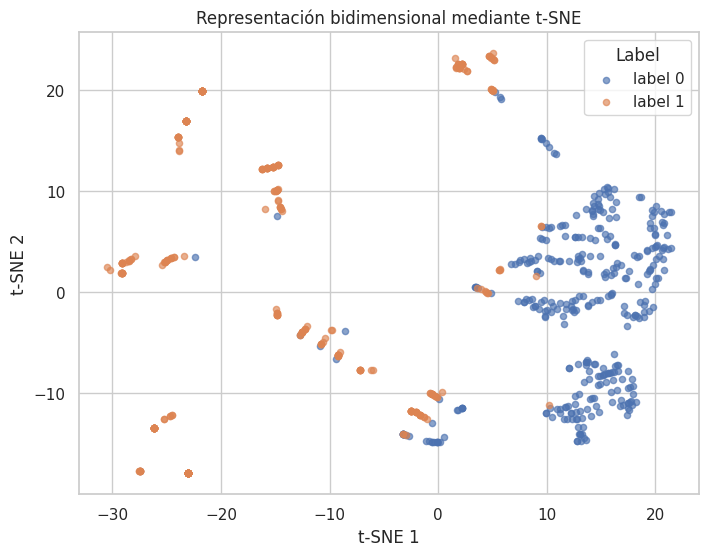

       TSNE1      TSNE2  label
0  13.242763 -13.995316      0
1 -26.191189 -13.438121      1
2  14.869898  -8.285705      0
3 -23.015312 -17.919910      1
4 -10.873445  -5.321335      0


In [12]:

# Aplicar t-SNE
# t-SNE es más costoso que PCA, por lo que se utiliza una muestra estratificada.
# Esto permite visualizar la estructura local sin hacer que la ejecución sea excesivamente lenta.

sample_size = min(700, len(scaled_df))
_, tsne_sample = train_test_split(
    scaled_df,
    test_size=sample_size,
    random_state=RANDOM_STATE,
    stratify=scaled_df['label']
)

tsne_X = tsne_sample[feature_cols].values
tsne_y = tsne_sample['label'].values

print('Tamaño de la muestra usada en t-SNE:', tsne_X.shape)

# Se usa method='exact' porque en algunos entornos de ejecución es más estable para muestras pequeñas.
try:
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        learning_rate='auto',
        init='pca',
        max_iter=500,
        random_state=RANDOM_STATE,
        method='exact'
    )
except TypeError:
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        learning_rate='auto',
        init='pca',
        n_iter=500,
        random_state=RANDOM_STATE,
        method='exact'
    )

X_tsne = tsne.fit_transform(tsne_X)

# Crear un DataFrame con los resultados de t-SNE
tsne_df = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'])
tsne_df['label'] = tsne_y

# Visualizar los resultados de t-SNE
plt.figure(figsize=(8, 6))
for label_value in sorted(tsne_df['label'].unique()):
    subset = tsne_df[tsne_df['label'] == label_value]
    plt.scatter(subset['TSNE1'], subset['TSNE2'], s=20, alpha=0.65, label=f'label {label_value}')
plt.title('Representación bidimensional mediante t-SNE')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Label')
plt.show()

print(tsne_df.head().to_string())


#### Análisis de los resultados obtenidos por t-SNE

t-SNE se ha aplicado sobre una muestra de 700 observaciones para mantener un tiempo de ejecución razonable. La representación obtenida muestra agrupamientos visibles y una separación apreciable entre las etiquetas, lo que indica que existen relaciones locales útiles entre las observaciones.

A diferencia de PCA, las coordenadas de t-SNE no deben interpretarse como combinaciones lineales de variables originales. Su valor principal está en la visualización: puntos cercanos en el mapa tienden a representar observaciones similares. Por ello, t-SNE resulta útil para inspeccionar la estructura local del dataset, aunque no permite explicar cada eje de forma tan directa como PCA.

### Utilizar t-SNE para clasificar

#### Evaluación exploratoria sobre t-SNE

Se comprueba si la representación obtenida por t-SNE permite separar las etiquetas con un clasificador simple. Esta prueba se interpreta con prudencia, porque t-SNE está pensado principalmente como herramienta de visualización y depende de la muestra y de sus hiperparámetros.

Accuracy usando la representación t-SNE: 0.9429

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        88
           1       0.93      0.95      0.94        87

    accuracy                           0.94       175
   macro avg       0.94      0.94      0.94       175
weighted avg       0.94      0.94      0.94       175



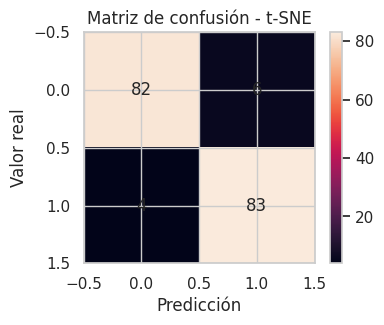

In [13]:

# Dividir los datos en conjunto de entrenamiento y prueba
X_train_tsne, X_test_tsne, y_train_tsne, y_test_tsne = train_test_split(
    tsne_df[['TSNE1', 'TSNE2']],
    tsne_df['label'],
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=tsne_df['label']
)

# Entrenar un modelo de clasificación sencillo sobre las dos dimensiones t-SNE
rf_tsne = RandomForestClassifier(n_estimators=80, random_state=RANDOM_STATE, n_jobs=-1)
rf_tsne.fit(X_train_tsne, y_train_tsne)

# Predecir y evaluar el modelo
y_pred_tsne = rf_tsne.predict(X_test_tsne)
acc_tsne = accuracy_score(y_test_tsne, y_pred_tsne)

print('Accuracy usando la representación t-SNE:', round(acc_tsne, 4))
print('\nInforme de clasificación:')
print(classification_report(y_test_tsne, y_pred_tsne))

cm_tsne = confusion_matrix(y_test_tsne, y_pred_tsne)
plt.figure(figsize=(4, 3))
plt.imshow(cm_tsne)
plt.title('Matriz de confusión - t-SNE')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.colorbar()
for i in range(cm_tsne.shape[0]):
    for j in range(cm_tsne.shape[1]):
        plt.text(j, i, cm_tsne[i, j], ha='center', va='center')
plt.show()


#### ¿Se puede utilizar la reducción de dimensionalidad obtenida por t-SNE para entrenar un algoritmo de clasificación?

Técnicamente sí se puede entrenar un clasificador usando las dos coordenadas generadas por t-SNE. En el notebook se realiza esta comprobación mediante un Random Forest y se obtiene una accuracy de 0,9429 sobre la muestra analizada.

Sin embargo, este resultado debe interpretarse con cautela. t-SNE está diseñado principalmente para visualización y no para generar variables estables de clasificación. Su representación depende de la muestra, de la inicialización y de parámetros como la perplejidad. Por tanto, aunque en este caso las coordenadas permiten separar bastante bien las etiquetas, PCA ofrece una alternativa más interpretable y estable para construir una representación reducida.

### LDA

#### Aplicación de LDA al texto

LDA se aplica a la columna `comentario` para identificar temas latentes a partir de las palabras del corpus. Esta parte complementa el análisis numérico, ya que permite interpretar el contenido textual del dataset.

In [14]:

# Aplicación de LDA sobre la columna 'comentario'
# En este apartado se utiliza LDA como Latent Dirichlet Allocation para extraer temas.
# Para que la ejecución sea razonable, el modelo de temas se ajusta sobre una muestra estratificada.

text_data_full = data[['comentario', 'label']].copy()
text_data_full['comentario'] = text_data_full['comentario'].fillna('').astype(str)
text_data_full['label'] = text_data_full['label'].astype(int)

lda_sample_size = min(1500, len(text_data_full))
_, text_data = train_test_split(
    text_data_full,
    test_size=lda_sample_size,
    random_state=RANDOM_STATE,
    stratify=text_data_full['label']
)
text_data = text_data.reset_index(drop=True)

print('Tamaño de la muestra usada para LDA global:', text_data.shape)

# Lista sencilla de palabras vacías en español. El dataset ya está bastante preprocesado,
# pero se añade este filtro para mejorar la interpretabilidad de los temas.
spanish_stopwords = [
    'de', 'la', 'que', 'el', 'en', 'y', 'a', 'los', 'del', 'se', 'las', 'por', 'un', 'para',
    'con', 'no', 'una', 'su', 'al', 'lo', 'es', 'como', 'más', 'mas', 'pero', 'sus', 'le',
    'ya', 'o', 'este', 'sí', 'porque', 'esta', 'entre', 'cuando', 'muy', 'sin', 'sobre',
    'también', 'tambien', 'me', 'hasta', 'hay', 'donde', 'quien', 'desde', 'todo', 'nos',
    'durante', 'todos', 'uno', 'les', 'ni', 'contra', 'otros', 'ese', 'eso', 'ante', 'ellos',
    'e', 'esto', 'mi', 'antes', 'algunos', 'unos', 'otro', 'otras', 'otra', 'estos', 'mucho',
    'nada', 'muchos', 'cual', 'poco', 'estar', 'estas', 'algo'
]

vectorizer = CountVectorizer(
    max_features=400,
    min_df=3,
    max_df=0.90,
    stop_words=spanish_stopwords,
    token_pattern=r'(?u)\b\w\w+\b'
)

X_words = vectorizer.fit_transform(text_data['comentario'])
terms = np.array(vectorizer.get_feature_names_out())

lda = LatentDirichletAllocation(
    n_components=5,
    random_state=RANDOM_STATE,
    learning_method='online',
    max_iter=5,
    batch_size=128
)

lda.fit(X_words)

# Mostrar los temas
n_top_words = 12
topics_global = []

for topic_idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[::-1][:n_top_words]
    top_words = terms[top_indices]
    topics_global.append({
        'topic': topic_idx,
        'palabras_representativas': ', '.join(top_words)
    })
    print(f"Tema {topic_idx}: {', '.join(top_words)}")

topics_global_df = pd.DataFrame(topics_global)
print(topics_global_df.to_string(index=False))


Tamaño de la muestra usada para LDA global: (1500, 2)


Tema 0: dia, año, gobierno, poder, hoy, abc, españa, hora, ser, nuevo, primero, persona
Tema 1: poder, cientifico, solo, hacer, año, ser, sistema, ciencia, decir, fisico, materia, forma
Tema 2: año, hacer, ser, español, poder, españa, obra, gobierno, primero, proyecto, publico, politico
Tema 3: año, poder, agua, estudio, segun, caso, enfermedad, dato, investigacion, cientifico, persona, hacer
Tema 4: hacer, año, poder, ser, vez, dos, primero, solo, decir, tanto, mismo, vida
 topic                                                                            palabras_representativas
     0                     dia, año, gobierno, poder, hoy, abc, españa, hora, ser, nuevo, primero, persona
     1           poder, cientifico, solo, hacer, año, ser, sistema, ciencia, decir, fisico, materia, forma
     2       año, hacer, ser, español, poder, españa, obra, gobierno, primero, proyecto, publico, politico
     3 año, poder, agua, estudio, segun, caso, enfermedad, dato, investigacion, cientifico, p

#### Análisis global de LDA

LDA identifica cinco temas globales a partir de la columna `comentario`. Los términos más representativos incluyen palabras como `año`, `hacer`, `poder`, `gobierno`, `españa`, `cientifico`, `estudio` y `enfermedad`. Esto indica que los comentarios contienen vocabulario asociado a temas generales, políticos, sociales y científicos.

Los temas globales presentan cierto solapamiento, ya que varias palabras frecuentes aparecen en más de un tema. Esto es habitual cuando el corpus contiene términos comunes o textos con vocabulario compartido. Aun así, LDA permite obtener una primera organización temática del contenido textual y complementar la información numérica utilizada en PCA y t-SNE.

### LDA en función del label

#### LDA por etiqueta

Se ajusta LDA por separado para cada valor de `label`. De este modo se comparan los términos característicos de cada clase y se observa si existen diferencias relevantes en el vocabulario asociado a cada etiqueta.

In [15]:

# Definir función para aplicar LDA y obtener temas por cada etiqueta

def aplicar_lda_por_label(df_label, label_value, n_topics=3, n_words=12):
    # Se toma una muestra por etiqueta para mantener un tiempo de ejecución adecuado.
    sample_label = df_label.sample(min(400, len(df_label)), random_state=RANDOM_STATE).reset_index(drop=True)
    
    vectorizer_label = CountVectorizer(
        max_features=250,
        min_df=2,
        max_df=0.95,
        stop_words=spanish_stopwords,
        token_pattern=r'(?u)\b\w\w+\b'
    )
    
    X_label_words = vectorizer_label.fit_transform(sample_label['comentario'])
    terms_label = np.array(vectorizer_label.get_feature_names_out())
    
    lda_label = LatentDirichletAllocation(
        n_components=n_topics,
        random_state=RANDOM_STATE,
        learning_method='online',
        max_iter=3,
        batch_size=64
    )
    lda_label.fit(X_label_words)
    
    rows = []
    for topic_idx, topic in enumerate(lda_label.components_):
        top_indices = topic.argsort()[::-1][:n_words]
        top_words = terms_label[top_indices]
        rows.append({
            'label': label_value,
            'topic': topic_idx,
            'palabras_representativas': ', '.join(top_words)
        })
    
    return pd.DataFrame(rows), lda_label, vectorizer_label

# Aplicar LDA por cada etiqueta de label y guardar en archivos CSV
lda_label_results = []
lda_models_by_label = {}
vectorizers_by_label = {}

for label_value in sorted(text_data_full['label'].unique()):
    subset = text_data_full[text_data_full['label'] == label_value].copy()
    topics_df, lda_label_model, vectorizer_label_model = aplicar_lda_por_label(
        subset,
        label_value=label_value,
        n_topics=2,
        n_words=12
    )
    
    lda_label_results.append(topics_df)
    lda_models_by_label[label_value] = lda_label_model
    vectorizers_by_label[label_value] = vectorizer_label_model
    
    output_name = f'lda_topics_label_{label_value}.csv'
    topics_df.to_csv(output_name, index=False, encoding='utf-8')
    print(f'Archivo generado: {output_name}')
    print(topics_df.to_string(index=False))

lda_by_label_df = pd.concat(lda_label_results, ignore_index=True)
print(lda_by_label_df.to_string(index=False))


Archivo generado: lda_topics_label_0.csv
 label  topic                                                   palabras_representativas
     0      0 año, hacer, poder, ser, dia, nuevo, dos, primero, tras, hoy, españa, tanto
     0      1  poder, hacer, año, ser, solo, vez, decir, seguir, mismo, dos, tiempo, ver
Archivo generado: lda_topics_label_1.csv
 label  topic                                                                                  palabras_representativas
     1      0                         gente, hacer, politico, españa, inutil, dar, ser, poder, puta, tonto, decir, asco
     1      1 español, mierdo, informativo, gobierno, pais, verguenza, sinverguenza, mismo, menudo, imbecil, vivir, ser
 label  topic                                                                                  palabras_representativas
     0      0                                año, hacer, poder, ser, dia, nuevo, dos, primero, tras, hoy, españa, tanto
     0      1                                 poder

#### Bolsa de palabras por etiqueta

La bolsa de palabras resume los términos más frecuentes en cada clase. Esta salida facilita una interpretación directa del contenido textual y sirve como apoyo para las conclusiones del análisis LDA.

Distribución relativa de temas globales por etiqueta en la muestra analizada:
topic_global      0      1      2      3      4
label                                          
0             0.253  0.117  0.156  0.141  0.332
1             0.473  0.081  0.081  0.044  0.320


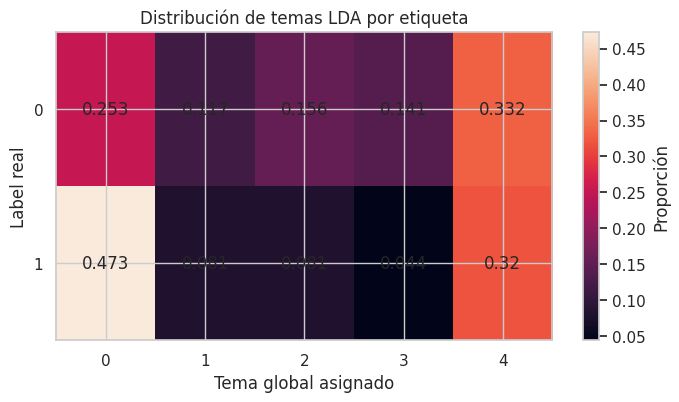

Bolsa de palabras más frecuente por etiqueta:
 label   palabra  frecuencia
     0     poder        3914
     0       año        3450
     0     hacer        3249
     0       ser        2562
     0   primero        1781
     0     nuevo        1732
     0       dos        1701
     0      solo        1547
     0       dia        1434
     0       vez        1418
     0     mismo        1388
     0     decir        1305
     0     parte        1180
     0    seguir        1149
     0    tiempo        1093
     0     ahora        1088
     0     segun        1079
     0     mundo        1055
     0   persona        1000
     0       asi        1000
     1     hacer         137
     1       ser         103
     1     poder         100
     1      puto          82
     1    españa          79
     1     decir          78
     1      puta          68
     1  gobierno          68
     1       ver          65
     1    mierdo          64
     1      hijo          62
     1      pais          

In [16]:

# Generar bolsas de palabras para cada tema y comparar su distribución con las etiquetas reales
# En este caso, primero se asigna a cada comentario de la muestra LDA su tema global más probable.

doc_topic_distribution = lda.transform(X_words)
text_data['topic_global'] = doc_topic_distribution.argmax(axis=1)

# Distribución de temas por etiqueta real
topic_label_table = pd.crosstab(
    text_data['label'],
    text_data['topic_global'],
    normalize='index'
).round(3)

print('Distribución relativa de temas globales por etiqueta en la muestra analizada:')
print(topic_label_table.to_string())

plt.figure(figsize=(8, 4))
plt.imshow(topic_label_table, aspect='auto')
plt.colorbar(label='Proporción')
plt.title('Distribución de temas LDA por etiqueta')
plt.xlabel('Tema global asignado')
plt.ylabel('Label real')
plt.xticks(range(topic_label_table.shape[1]), topic_label_table.columns)
plt.yticks(range(topic_label_table.shape[0]), topic_label_table.index)
for i in range(topic_label_table.shape[0]):
    for j in range(topic_label_table.shape[1]):
        plt.text(j, i, topic_label_table.iloc[i, j], ha='center', va='center')
plt.show()

# Bolsa de palabras simple por etiqueta: palabras más frecuentes en cada clase.
# Se calcula sobre una muestra por etiqueta para que el proceso sea rápido y reproducible.
bow_rows = []
for label_value in sorted(text_data_full['label'].unique()):
    subset = text_data_full[text_data_full['label'] == label_value].sample(
        min(1500, (text_data_full['label'] == label_value).sum()),
        random_state=RANDOM_STATE
    )
    vectorizer_bow = CountVectorizer(
        max_features=20,
        min_df=3,
        stop_words=spanish_stopwords,
        token_pattern=r'(?u)\b\w\w+\b'
    )
    X_bow = vectorizer_bow.fit_transform(subset['comentario'])
    words = np.array(vectorizer_bow.get_feature_names_out())
    freqs = np.asarray(X_bow.sum(axis=0)).ravel()
    order = freqs.argsort()[::-1]
    
    for word, freq in zip(words[order], freqs[order]):
        bow_rows.append({
            'label': label_value,
            'palabra': word,
            'frecuencia': int(freq)
        })

bow_by_label = pd.DataFrame(bow_rows)
print('Bolsa de palabras más frecuente por etiqueta:')
print(bow_by_label.to_string(index=False))

bow_by_label.to_csv('bolsa_palabras_por_label.csv', index=False, encoding='utf-8')
print('Archivo generado: bolsa_palabras_por_label.csv')


#### Análisis de LDA por etiqueta y bolsas de palabras

El análisis por etiqueta permite observar diferencias entre los textos asociados a `label = 0` y `label = 1`. En `label = 0` aparecen con frecuencia términos más generales como `año`, `hacer`, `poder`, `ser`, `día`, `nuevo` o `primero`. En `label = 1` aparecen términos con mayor carga valorativa o política, como `gente`, `político`, `españa`, `inútil`, `gobierno` o `país`.

La distribución relativa de temas también muestra diferencias entre clases. En la muestra analizada, `label = 1` concentra una proporción mayor en el tema global 0, mientras que `label = 0` aparece más repartida entre varios temas. Esto sugiere que las clases no solo se diferencian por las variables numéricas, sino también por ciertos patrones de vocabulario.

#### Comparación final

La comparación final reúne los resultados de PCA, t-SNE y LDA. PCA y t-SNE permiten analizar la estructura numérica del dataset en dos dimensiones, mientras que LDA aporta una interpretación textual mediante temas y palabras representativas.

### Conclusiones finales

El análisis muestra que PCA y t-SNE permiten representar el dataset en dos dimensiones manteniendo una separación clara entre las dos etiquetas. PCA conserva el 71,86 % de la varianza en las dos primeras componentes y ofrece una representación interpretable, ya que sus ejes pueden relacionarse con las variables originales. Además, la clasificación exploratoria sobre `PC1` y `PC2` obtiene una accuracy de 0,9728, lo que indica que estas dos componentes resumen información muy relevante del dataset.

t-SNE también genera una visualización útil y obtiene una accuracy exploratoria de 0,9429 en la muestra utilizada. Su principal ventaja es que permite observar relaciones locales y agrupamientos no necesariamente lineales. Sin embargo, sus coordenadas son menos interpretables y más dependientes de la muestra y de los hiperparámetros.

LDA complementa el análisis al trabajar con la columna textual `comentario`. El análisis global identifica temas latentes en el corpus, y el análisis por etiqueta muestra diferencias de vocabulario entre las dos clases. En conjunto, PCA resulta la técnica más adecuada cuando se busca una reducción de dimensionalidad interpretable y estable, mientras que t-SNE es especialmente útil como herramienta visual. LDA aporta una interpretación adicional del contenido textual del dataset.